# CareerPilot AI — Phase 3D-2: Interview Coach AI Engine Development

## 1. Problem Definition
The CareerPilot AI Interview Coach evaluates written student and fresh-graduate interview answers across four categories:
- **Behavioral (`behavioral`)** and **Graduate & Culture Fit (`general`)**: Evaluated on Question Relevance, **STAR Completeness** (Situation, Task, Action, Result), Behavioral Theme Coverage, Clarity & Communication, and Practical Application.
- **Technical (`frontend`, `dsa`)**: Evaluated on Question Relevance, **Conceptual Understanding**, **Completeness**, Clarity & Communication, and Practical Application.

**Important:** Scores represent transparent rubric and semantic alignment signals — **not** predictions of interview selection or hiring probability.


## 2. Dataset Exploration (Curated Development Benchmark)
Because public interview datasets lack human-graded rubric scores for STAR completeness and conceptual depth, we created **20 PII-free curated development/evaluation test cases** spanning all 4 categories and multiple quality tiers (`strong`, `paraphrased`, `partial`, `missing_result`, `vague`, `one_word`, `long_repetitive`, `off_topic`).


In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from interview_coach import InterviewCoachEngine, QUESTION_BANK
from evaluate_interview_coach import BENCHMARK_CASES, benchmark_models, run_functional_tests

# CareerPilot AI Pastel Palette
PASTEL_LAVENDER = "#A78BCE"
PASTEL_BLUE = "#7FB3D5"
PASTEL_GREEN = "#7CC49B"
PASTEL_PINK = "#E295B0"
PASTEL_PEACH = "#E8B794"
CHARCOAL = "#262233"

plt.rcParams["figure.facecolor"] = "#FFFFFF"
plt.rcParams["axes.facecolor"] = "#FBF9FF"
plt.rcParams["axes.edgecolor"] = "#D5C9E8"
plt.rcParams["text.color"] = CHARCOAL
plt.rcParams["axes.labelcolor"] = CHARCOAL
plt.rcParams["xtick.color"] = CHARCOAL
plt.rcParams["ytick.color"] = CHARCOAL

cat_counts = {}
for tc in BENCHMARK_CASES:
    cat_counts[tc["category"]] = cat_counts.get(tc["category"], 0) + 1
print("Benchmark cases by category:", cat_counts)
print("Total curated cases:", len(BENCHMARK_CASES))


Benchmark cases by category: {'behavioral': 5, 'frontend': 5, 'dsa': 5, 'general': 5}
Total curated cases: 20


## 3. Preprocessing & Sentence Segmentation
Answers are normalized for whitespace, safely bounded at `6,000` characters, and segmented into sentences for sentence-level STAR and concept alignment.


In [2]:
sample_text = BENCHMARK_CASES[0]["answer"]
cleaned, truncated = InterviewCoachEngine._clean_text(sample_text, 6000)
sents = InterviewCoachEngine._split_sentences(cleaned)
print(f"Sentences: {len(sents)} | Truncated: {truncated}")
for i, s in enumerate(sents, 1):
    print(f"  {i}. {s}")


Sentences: 5 | Truncated: False
  1. During my capstone project last semester, our course planner stopped syncing saved schedules right before our demo.
  2. My task was to find the root cause and fix it within one day.
  3. I reproduced the bug locally, inspected browser storage writes, and wrote unit tests that revealed a stale state overwrite.
  4. I refactored the state updater and verified every edge case.
  5. As a result, the sync bug was completely resolved and our team delivered the demo on time.


## 4. Three-Way Model Benchmarking (`BAAI/bge-small-en-v1.5` vs `all-MiniLM-L6-v2` vs `TF-IDF`)
We benchmark all three approaches on the exact same 20-case dataset, comparing mean similarity across `strong`, `paraphrased`, `partial`, and `off_topic` answers, separation (`strong - off_topic`), and CPU inference latency.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

{
  "BAAI/bge-small-en-v1.5": {
    "load_seconds": 13.995,
    "avg_inference_ms_per_pair": 93.0,
    "mean_similarity_by_tier": {
      "strong": 0.766,
      "paraphrased": 0.6993,
      "partial": 0.7355,
      "off_topic": 0.4585
    },
    "strong_minus_offtopic": 0.3075,
    "paraphrased_minus_offtopic": 0.2408
  },
  "all-MiniLM-L6-v2": {
    "load_seconds": 0.964,
    "avg_inference_ms_per_pair": 58.55,
    "mean_similarity_by_tier": {
      "strong": 0.4983,
      "paraphrased": 0.2803,
      "partial": 0.5302,
      "off_topic": 0.0644
    },
    "strong_minus_offtopic": 0.4339,
    "paraphrased_minus_offtopic": 0.2159
  },
  "TF-IDF Baseline": {
    "load_seconds": 0.0,
    "avg_inference_ms_per_pair": 5.56,
    "mean_similarity_by_tier": {
      "strong": 0.1779,
      "paraphrased": 0.0,
      "partial": 0.1459,
      "off_topic": 0.0
    },
    "strong_minus_offtopic": 0.1779,
    "paraphrased_minus_offtopic": 0.0
  }
}


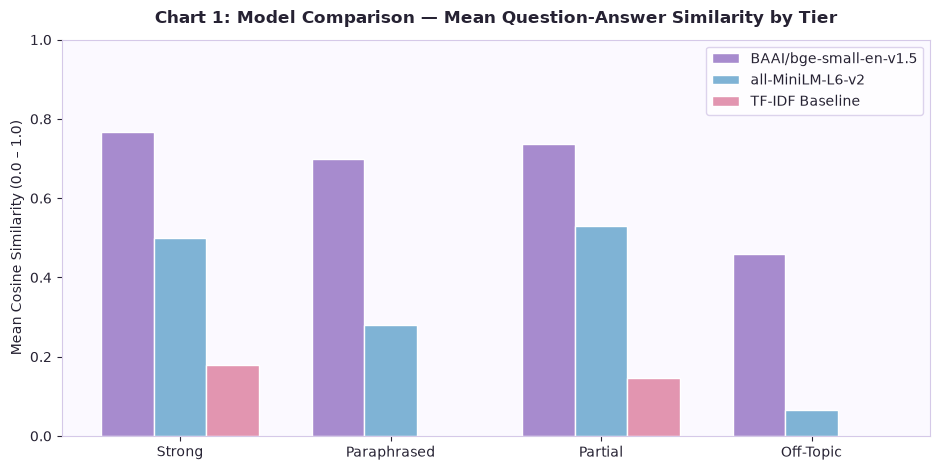

In [3]:
model_bench = benchmark_models()
print(json.dumps(model_bench, indent=2))

# Chart 1: Model Comparison (Grouped Bar Chart)
tiers = ["strong", "paraphrased", "partial", "off_topic"]
tier_labels = ["Strong", "Paraphrased", "Partial", "Off-Topic"]
bge_vals = [model_bench["BAAI/bge-small-en-v1.5"]["mean_similarity_by_tier"][t] for t in tiers]
mini_vals = [model_bench["all-MiniLM-L6-v2"]["mean_similarity_by_tier"][t] for t in tiers]
lex_vals = [model_bench["TF-IDF Baseline"]["mean_similarity_by_tier"][t] for t in tiers]

x = np.arange(len(tiers))
w = 0.25

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.bar(x - w, bge_vals, w, label="BAAI/bge-small-en-v1.5", color=PASTEL_LAVENDER, edgecolor="#FFFFFF")
ax.bar(x, mini_vals, w, label="all-MiniLM-L6-v2", color=PASTEL_BLUE, edgecolor="#FFFFFF")
ax.bar(x + w, lex_vals, w, label="TF-IDF Baseline", color=PASTEL_PINK, edgecolor="#FFFFFF")

ax.set_title("Chart 1: Model Comparison — Mean Question-Answer Similarity by Tier", fontweight="bold", pad=12)
ax.set_ylabel("Mean Cosine Similarity (0.0 – 1.0)")
ax.set_ylim(0, 1.0)
ax.set_xticks(x)
ax.set_xticklabels(tier_labels)
ax.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#D5C9E8")
plt.tight_layout()
plt.show()


## 5. Model Selection Based on Measured Evidence
We select the model with the strongest combined separation between relevant (`strong` + `paraphrased`) and `off_topic` answers while keeping fast local CPU inference.


In [4]:
bge_sep = model_bench["BAAI/bge-small-en-v1.5"]["strong_minus_offtopic"] + model_bench["BAAI/bge-small-en-v1.5"]["paraphrased_minus_offtopic"]
mini_sep = model_bench["all-MiniLM-L6-v2"]["strong_minus_offtopic"] + model_bench["all-MiniLM-L6-v2"]["paraphrased_minus_offtopic"]
selected_model = "BAAI/bge-small-en-v1.5" if bge_sep >= mini_sep else "all-MiniLM-L6-v2"
print(f"BGE separation={bge_sep:.4f} | MiniLM separation={mini_sep:.4f} -> Selected: {selected_model}")

engine = InterviewCoachEngine()
print("Engine model source:", engine.model_source)


BGE separation=0.5483 | MiniLM separation=0.6498 -> Selected: all-MiniLM-L6-v2
Engine model source: D:\CareerPilot AI\ml\InterviewCoach\models\all-MiniLM-L6-v2


## 6. STAR Component Coverage (Behavioral & General)
We evaluate STAR component detection (`Situation`, `Task`, `Action`, `Result`) across all behavioral and general benchmark cases.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

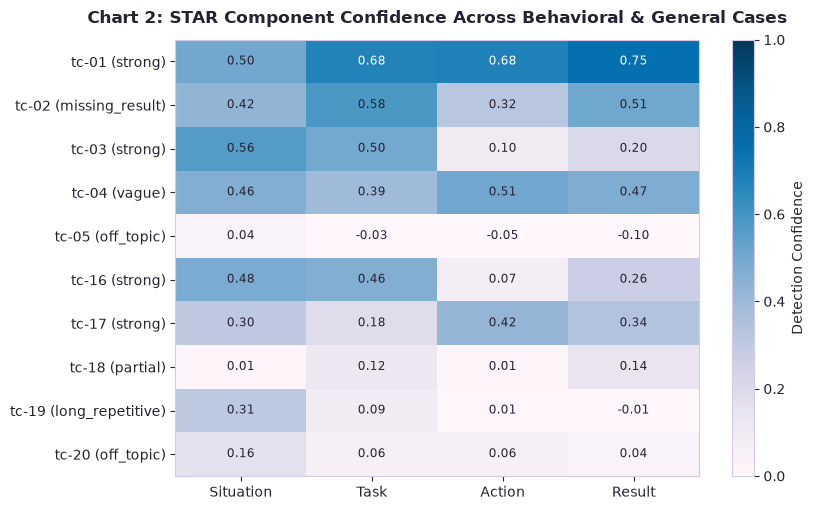

In [5]:
beh_cases = [tc for tc in BENCHMARK_CASES if tc["category"] in {"behavioral", "general"}]
star_comps = ["situation", "task", "action", "result"]
matrix = []
beh_labels = []

for tc in beh_cases:
    res = engine.evaluate(tc["answer"], tc["category"], question_id=tc["question_id"])
    beh_labels.append(f"{tc['id']} ({tc['tier']})")
    matrix.append([res["star_assessment"][c]["confidence"] for c in star_comps])

mat_np = np.array(matrix)

# Chart 2: STAR Component Coverage Heatmap (Pastel Purple Colormap)
fig, ax = plt.subplots(figsize=(8.5, 5.2))
im = ax.imshow(mat_np, cmap="PuBu", aspect="auto", vmin=0.0, vmax=1.0)
ax.set_xticks(np.arange(len(star_comps)))
ax.set_xticklabels([c.title() for c in star_comps])
ax.set_yticks(np.arange(len(beh_labels)))
ax.set_yticklabels(beh_labels)
ax.set_title("Chart 2: STAR Component Confidence Across Behavioral & General Cases", fontweight="bold", pad=12)

for i in range(len(beh_labels)):
    for j in range(len(star_comps)):
        val = mat_np[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color="#FFFFFF" if val > 0.62 else CHARCOAL, fontsize=8.5)

fig.colorbar(im, ax=ax, label="Detection Confidence")
plt.tight_layout()
plt.show()


## 7. Category-Aware Scoring & Dimension Breakdown
We inspect the rubric dimension contributions across representative technical and behavioral cases.


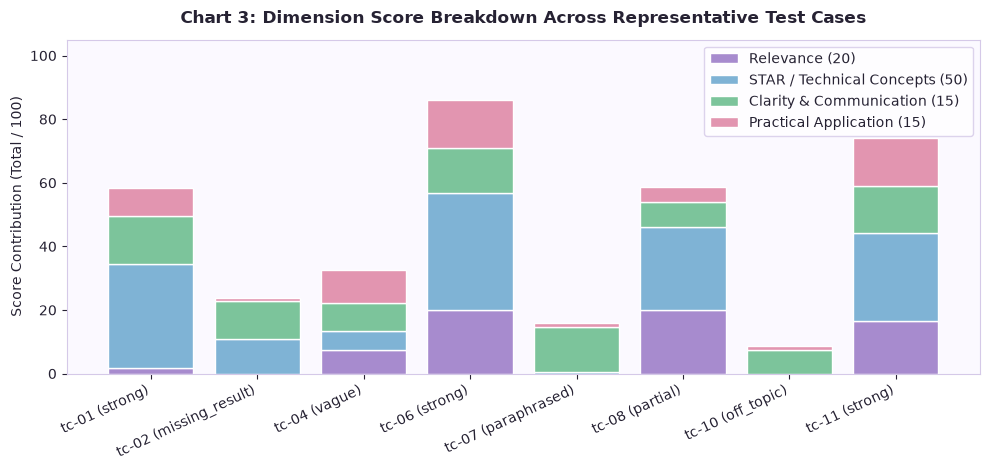

In [6]:
rep_ids = ["tc-01", "tc-02", "tc-04", "tc-06", "tc-07", "tc-08", "tc-10", "tc-11"]
rep_cases = [tc for tc in BENCHMARK_CASES if tc["id"] in rep_ids]

rel_pts, core_pts, clar_comm_pts, prac_pts, labels = [], [], [], [], []
for tc in rep_cases:
    res = engine.evaluate(tc["answer"], tc["category"], question_id=tc["question_id"])
    d = res["dimension_scores"]
    labels.append(f"{tc['id']} ({tc['tier']})")
    rel_pts.append(d["relevance"])
    if tc["category"] in {"behavioral", "general"}:
        core_pts.append(d["star_completeness"] + d["concept_coverage"])
    else:
        core_pts.append(d["conceptual_understanding"] + d["completeness"])
    clar_comm_pts.append(d["clarity"] + d["communication"])
    prac_pts.append(d["practical_application"])

# Chart 3: Dimension Score Breakdown (Stacked Bar Chart)
fig, ax = plt.subplots(figsize=(10, 4.8))
a1, a2, a3, a4 = np.array(rel_pts), np.array(core_pts), np.array(clar_comm_pts), np.array(prac_pts)
ax.bar(labels, a1, label="Relevance (20)", color=PASTEL_LAVENDER, edgecolor="#FFFFFF")
ax.bar(labels, a2, bottom=a1, label="STAR / Technical Concepts (50)", color=PASTEL_BLUE, edgecolor="#FFFFFF")
ax.bar(labels, a3, bottom=a1+a2, label="Clarity & Communication (15)", color=PASTEL_GREEN, edgecolor="#FFFFFF")
ax.bar(labels, a4, bottom=a1+a2+a3, label="Practical Application (15)", color=PASTEL_PINK, edgecolor="#FFFFFF")

ax.set_title("Chart 3: Dimension Score Breakdown Across Representative Test Cases", fontweight="bold", pad=12)
ax.set_ylabel("Score Contribution (Total / 100)")
ax.set_ylim(0, 105)
ax.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#D5C9E8", loc="upper right")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 8. Evaluation, Error Analysis & Artifact Export
We run the full functional test suite (`run_functional_tests`) and verify the saved local model and JSON artifacts.


In [7]:
func_report = run_functional_tests(engine)
print(f"Functional tests passed: {func_report['all_assertions_passed']} ({func_report['total_cases']} cases)")

artifacts_dir = Path("artifacts")
print("Saved artifacts:", [p.name for p in sorted(artifacts_dir.glob("*.json"))])
print("Saved models:", [p.name for p in sorted(Path("models").iterdir())])


Functional tests passed: True (20 cases)
Saved artifacts: ['evaluation_report.json', 'question_bank.json']
Saved models: ['all-MiniLM-L6-v2']


## 9. Limitations
- Embeddings capture semantic relevance rather than factual code correctness.
- Single-sentence behavioral answers may omit explicit STAR cues even when implicit context exists.
- Benchmark uses curated development examples rather than human-graded interview transcripts.
